---
---
# RANDOMNESS AND PROBABILITY

---
---

## ROADMAP: where we've been, and where we're going

In the last lecture we took *many* simple random samples from the Titanic data and studied the **sampling distribution** of an estimate. We learned that:

* estimates from random samples tend to land *near* the true population value,
* larger samples tend to provide estimates that land *closer* to the truth, but
* we can always get an unlucky sample whose estimate is far off.

Consider the words in the previous three statements: *"tend to"*, *"near"*, *"closer"*, *"unlucky"*, *"far off"*. These are vague terms, but data-driven decisions require something sharper; something more precise and quantifiable. 

This is what we do with **probability**, which you can think of as a language for communicating about uncertainty using *numbers* instead of vague words.

We ended the last lecture with a promise:

> *"In practice, we only have one sample. So, what can we do in that case? The answer is to build proxy sampling distributions and calculate confidence intervals. But before we do that, we need to learn about **probability**."*

This is where we begin now.


---
---

## Thinking Probabilistically

### 🗣 ACTIVITY: How likely is *likely*?

**THINK.** In the code cell below, replace each `np.nan` with a number between 0 to 100 reflecting what you think each phrase communicates when you read it in a news story or an official report. Go with your gut. Assume 0 means impossible and 100 means certain.

**PAIR.** Find a neighbour. Type their numbers into the second dictionary, then run the comparison cell. Which phrase do the two of you disagree about the most?

**SHARE.** We'll poll the room on the phrase *"real possibility"*. What range of answers do we get? How would you feel if that phrase appeared in a flood warning? In a medical report about your surgery?

In [7]:
# THINK: replace each np.nan with your own number between 0 and 100
import numpy as np
my_numbers = {
    "almost certain":   np.nan,
    "very likely":      np.nan,
    "likely":           np.nan,
    "real possibility": np.nan,
    "unlikely":         np.nan,
    "very unlikely":    np.nan,
    "almost no chance": np.nan
}

In [8]:
# PAIR: replace each np.nan with your neighbour's numbers
neighbour_numbers = {
    "almost certain":   np.nan,
    "very likely":      np.nan,
    "likely":           np.nan,
    "real possibility": np.nan,
    "unlikely":         np.nan,
    "very unlikely":    np.nan,
    "almost no chance": np.nan
}

In [9]:
# Compare your answers. Which phrase has the biggest disagreement?
import pandas as pd
comparison = pd.DataFrame({"Phrase": list(my_numbers.keys()),
                           "Me": list(my_numbers.values()),
                           "My Neighbour": list(neighbour_numbers.values())})
comparison["Absolute Difference"] = (comparison["Me"] - comparison["My Neighbour"]).abs()
comparison.sort_values(by = "Absolute Difference", ascending = False)

,Phrase,Me,My Neighbour,Absolute Difference
0,almost certain,NaN,NaN,NaN
1,very likely,NaN,NaN,NaN
2,likely,NaN,NaN,NaN
3,real possibility,NaN,NaN,NaN
4,unlikely,NaN,NaN,NaN
5,very unlikely,NaN,NaN,NaN
6,almost no chance,NaN,NaN,NaN


### Probability: a number that measures uncertainty

A **probability** is a number between 0 and 1 (also expressed between 0% and 100% as a **chance**) that **measures how likely an event is to occur**.

* A probability of 0 means the event is impossible.
* A probability of 1 means the event is certain.
* Probabilities between 0 and 1 measure degrees of *likelihood*. 
    * An event with probability close to 1 is more likely than an event with probability close to 0.
    * A probability of 0.5 expresses uncertainty in something like the toss of a fair coin: *heads* and *tails* are equally likely; they each have a 50% chance of happening.

We see statements involving probability all the time. 

* *There is an 80% chance of rain this afternoon.*
* *The odds of winning the lottery are 1 in 33 million.*
* *This common surgical procedure has a 98% success rate.*
* *The underdog team only has a 10% chance of making the playoffs this season.*

But what do these statements *actually mean*? That's what we're here to answer.

---
---

## The Language of Probability

To talk precisely about probability, we need some vocabulary.

### Random processes, outcomes, sample spaces, and events

* A **random process** is any process whose result we can't predict with certainty in advance, but whose possible results we *can list*. 
    * Important: random doesn't mean chaotic or mysterious, it just means *uncertain*. For example, a coin flip is random. We don't know what *will* happen but we do know what *can* happen.
* An **outcome** is one single, specific result of the random process.
* The **sample space** is the collection of all possible outcomes. 
    * Important: the term "sample" here is *completely distinct* from the term "sample" we've used to mean a subset of a population.
* An **event** is a statement about the outcome that is either true or false
    * We can also think of an event as a collection of outcomes.

| | Flip a coin | Roll a die | Pick one Titanic passenger at random |
|---|---|---|---|
| **Random process** | flip the coin | roll the die | `titanic.sample(n=1)` |
| **An outcome** | heads | a 4 | passenger number 1017 |
| **Sample space**| {heads, tails} | {1, 2, 3, 4, 5, 6} | all 2207 passengers and crew |
| **An event** | "the coin lands heads" | "the die shows an even number"| "the passenger survived" |

We can simulate each of these random processes using `python`. **Run each of the cells below several times** and watch the results change:

**A coin flip:**

In [118]:
np.random.choice(["heads", "tails"])

'tails'

**A die roll:**

In [119]:
np.random.choice([1, 2, 3, 4, 5, 6])

1

**One passenger picked at random from the Titanic data:**

In [120]:
titanic = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/titanic_passenger_info.csv")

In [124]:
titanic.sample(n = 1)

,gender,age,class,embarked,country,fare,sibsp,parch,survived
1326,male,24.0,engineering crew,Southampton,England,0.0,0.0,0.0,yes


Notice how we can't predict what any one run will give, but we *do* know all the things that could happen. That's what defines these random processes.

### Events are logical statements 

Previously, we filtered rows of a data frame using *logical statements*, like 

```python 
mlb_salaries["Team"] == "TOR"
```

We can use exactly the same idea to define **events** for the process "pick one passenger at random":

* an event is a logical (i.e., boolean) statement about the passenger,
* the passengers for whom the statement is `True` are all outcomes that compose the event.

Let's define four events about Titanic passengers, and collect them in one data frame so each *column* is an event:

In [125]:
survived    = (titanic["survived"] == "yes")
female      = (titanic["gender"] == "female")
child       = (titanic["age"] < 18)       
first_class = (titanic["class"] == "1st")

events = pd.DataFrame({"survived": survived,
                       "female": female,
                       "child": child,
                       "first_class": first_class})
events.head(10)

,survived,female,child,first_class
0,False,False,False,False
1,False,False,True,False
2,False,False,True,False
3,True,True,False,False
4,True,True,True,False
5,True,False,False,False
6,False,False,False,False
7,True,True,False,False
8,True,False,False,False
9,True,False,False,False


How many outcomes (passengers) satisfy each event? Summing counts the `True` values (`True` is treated numerically as `1` and `False` is treated numerically as `0`).

In [126]:
events.sum()

survived       711
female         489
child          200
first_class    324
dtype: int64

Combining events works just like combining logical statements. Given two events $A$ and $B$, here's how we map between plain English and Python:

* $A$ **and** $B$ (both events happen) is written `A & B`
* $A$ **or** $B$ (at least one of the events happens, possibly both) is written `A | B`
* **not** $A$ (event $A$ does *not* happen) is written `~A`
    * This one is new: the "tilde" `~` flips every `True` to `False` and vice versa.

In [16]:
# Passengers who were female AND survived
(female & survived).sum()

359

In [17]:
# Passengers who were female OR survived (or both)
(female | survived).sum()

841

In [18]:
# Passengers who did NOT survive
(~survived).sum()

1496

* Events $A$ and $B$ are **mutually exclusive** if they *cannot both happen* at the same time.
    * In other words: no outcome satisfies both events. For instance, a passenger can't be in both first class and second class:

In [19]:
second_class = (titanic["class"] == "2nd")
(first_class & second_class).sum()

0

Zero passengers are in both events, so "first class" and "second class" are mutually exclusive. On the other hand, "female" and "survived" are *not* mutually exclusive, since we found plenty of passengers who are both.

### Example: The sample space of two coins
Suppose we flip a coin *twice*. What's the sample space? Each outcome is a *pair* of results. A **nested `for` loop** (a loop inside a loop) can list them all: the inner loop runs *completely* for every step of the outer loop.

In [20]:
two_flips = []
for first_flip in ["H", "T"]:
    for second_flip in ["H", "T"]:
        two_flips.append(first_flip + second_flip)

two_flips

['HH', 'HT', 'TH', 'TT']

The sample space has 4 outcomes: {`HH`, `HT`, `TH`, `TT`}. 
* The event "*at least one head*" is satisfied by the collection {`HH`, `HT`, `TH`}, which contains 3 of the 4 outcomes.
* The event "*both flips match*" is satisfied by the collected {`HH`, `TT`}, which contains 2 of the 4 outcomes.

Now it's your turn to build a sample space.

### 💻 ACTIVITY: The sample space of two dice

Roll two dice, one red and one green. Each outcome is a pair (red number, green number).

1. Run the nested loop to build the sample space, and store it as a data frame `dice` with one row per outcome. How many outcomes are there?
2. Define three events as boolean columns, and count the outcomes in each:
    * `total_is_7`: the two dice add up to 7
    * `doubles`: both dice show the same number
    * `has_a_6`: at least one die shows a 6
3. Which pairs of these three events are mutually exclusive? Check using `&`.

In [129]:
# 1. Build the sample space (every (red, green) pair). How many outcomes are there?
sample_space = []
for red in range(1, 7):
    for green in range(1, 7):                    
        sample_space.append((red, green))
dice = pd.DataFrame(sample_space, columns = ["red", "green"])
print(dice)

    red  green
0     1      1
1     1      2
2     1      3
3     1      4
4     1      5
5     1      6
6     2      1
7     2      2
8     2      3
9     2      4
10    2      5
11    2      6
12    3      1
13    3      2
14    3      3
15    3      4
16    3      5
17    3      6
18    4      1
19    4      2
20    4      3
21    4      4
22    4      5
23    4      6
24    5      1
25    5      2
26    5      3
27    5      4
28    5      5
29    5      6
30    6      1
31    6      2
32    6      3
33    6      4
34    6      5
35    6      6


In [ ]:
# 2. Define the three events, then count how many outcomes are in each
total_is_7 = ____          # the two dice add up to 7
doubles    = ____          # both dice show the same number
has_a_6    = ____          # at least one die shows a 6
print(total_is_7.sum(), doubles.sum(), has_a_6.sum())

In [ ]:
# 3. Which pairs of events are mutually exclusive?
# Your code here

<details>
<summary><b>Show Solution</b></summary>

```python
# 1. How many outcomes?
print(len(dice))      

# 2. Define the events and count
total_is_7 = ((dice["red"] + dice["green"]) == 7)
doubles    = (dice["red"] == dice["green"])
has_a_6    = (dice["red"] == 6) | (dice["green"] == 6)
print(total_is_7.sum(), doubles.sum(), has_a_6.sum()) 

# 3. Overlaps
print((total_is_7 & doubles).sum())   
print((total_is_7 & has_a_6).sum())   
print((doubles & has_a_6).sum())     

```

The only mutually exclusive pair is `total_is_7` and `doubles`: doubles always add up to an even number, so they can never add up to 7.

</details>

We now have *counts* of the number of outcomes that define each event. Next we learn how to turn counts into probabilities.

---
---

## Interpreting Probabilities

When we say things like:

* *the probability that this coin lands heads is 0.5*, or
* *there's a 30% chance of rain tomorrow*, or
* *the probability that a Titanic passenger survived is 0.32*

what are we actually claiming about the world? To help understand this, we need to acknowledge that there are three common ways of defining and interpreting probabilities. 

---

### Definitions of Probability

Notation: Denote the event of interest by $A$. The probability of event $A$ is denoted $\text{Pr}(A)$.

1. The **classical** definition:
    * The probability of event $A$ is $$\text{Pr}(A)=\frac{\text{number of outcomes in the event } A}{\text{number of outcomes in the sample space}},$$ assuming all of the outcomes in the sample space are equally likely.
    * **Example:** When we flip a coin, the sample space is $\{\text{heads, tails}\}$, containing 2 outcomes. The event "heads" is defined by the single outcome "heads". The probability of tossing a fair coin and it landing heads is $$\text{Pr(heads)} = \frac{1}{2}$$
    * **Example:** When we toss a coin twice, what's the probability that we get at least one head? $$\text{Pr(at least one head)} = \frac{3}{4}$$
    * **Example:** When we toss a coin twice, what's the probability that we see the same face on both tosses? $$\text{Pr(same face)} = \frac{2}{4}$$
    * **Example:** When we roll a 6-sided die, what's the probability that we get an even number? $$\text{Pr(even number)} = \frac{3}{6}$$

2. The **relative frequency** definition:
    * The probability of an event is the proportion of times the event occurs in a *very long* series of repetitions of the random process.
    * The *relative frequency* of an event $A$ after $N$ repetitions of the random process is $$\text{relative frequency of } A = \frac{\text{number of repetitions in which } A \text{ occurred}}{N}.$$
    * The probability of $A$ is the value this relative frequency converges to as we repeat the process more and more times (in the long run): $$P(A) = \text{the long-run relative frequency of } A.$$
    * **Example:** If you flip a coin 10 times, you may not get exactly 5 heads and 5 tails. But if you flip a coin 100 times, 1000 times, 10000 times you'll get closer and closer to exactly 50% heads and 50% tails.
    * **Example:** If you toss a 6-sided die *many* times, the proportion (relative frequency) of times you get a 3 will approach $$\text{Pr(roll a 3)} = \frac{1}{6}$$.
    * **Example:** If you run *many* weather models which are meant to predict tomorrow's weather, the proportion (relative frequency) of models that predict rain is used to estimate the probability that it rains tomorrow.
    
3. The **subjective probability** definition:
    * The probability of an event $A$ is a measure of how sure the person making the statement is that event $A$ will happen.
    * This is informal, un-objective, and frankly not worth studying scientifically.
    * **Example:**  A sports fan states that their favorite team has a 25% chance of winning the championship this year, based on loyalty and optimism rather than statistical reasoning.

We'll focus primarily on the **relative frequency interpretation** in this course, because it's the backbone of statistical inference: repeating a random process again and again is *exactly* what we did with repeated samples in the last lecture.

But we'll also consider the classical definition to build confidence in the relative frequency interpretation.

---

### 🗣 ACTIVITY: What does "probability" mean here?

Discuss with your neighbours. For each statement, decide which probability definition aligns best, and discuss what is being communicated.

1. *"A fair coin lands heads with probability 0.5."*
2. *"A randomly chosen Titanic passenger survived with probability 0.32."*
3. *"There's a 30% chance of rain in Waterloo tomorrow."*
4. *"The Toronto Blue Jays will win the 2027 World Series with probability 0.10."*

---

### Watching probability emerge: coin flips

Recall, the probability of flipping a coin and it coming up heads is 0.5. This can be obtained using the classifical definition of probability: there are 2 equally likely outcomes and 1 of them is heads. 

Let's repeat the random process of flipping a coin (through simulation) to appreciate the relative frequency definition.

First, simulate $N$ flips of a fair coin (`1` = heads, `0` = tails) and compute the relative frequency of heads. Run this cell several times:

In [130]:
import numpy as np

N = 10
flips = np.random.randint(low = 0, high = 2, size = N) 
print(flips)
print("Relative frequency of heads:", flips.mean())

[1 0 1 0 1 0 0 0 0 1]
Relative frequency of heads: 0.4


With only 10 flips, the relative frequency bounces around quite a bit. What happens as we flip more and more?

In [131]:
N_values = [10, 100, 1000, 10000, 100000, 1000000]
rel_freqs = []
for N in N_values:
    flips = np.random.randint(low = 0, high = 2, size = N)
    rel_freqs.append(flips.mean())

pd.DataFrame({"Number of flips": N_values,
              "Relative frequency of heads": rel_freqs})

,Number of flips,Relative frequency of heads
0,10,0.20000
1,100,0.54000
2,1000,0.47300
3,10000,0.49830
4,100000,0.49961
5,1000000,0.49973


The relative frequency reliably gets closer to 0.5 as $N$ gets bigger. Let's take a closer look at this. 

Below we flip a coin 2000 times, and after every flip we recompute the relative frequency of heads *so far*. We do this five times, to see five different "runs."

* `np.cumsum()` computes a *cumulative sum* (i.e., a *running total*). For example, `[1, 0, 1, 1]` becomes `[1, 1, 2, 3]`. So `np.cumsum(flips)` is the number of heads *so far*.
* Dividing by the number of flips so far gives the relative frequency so far.

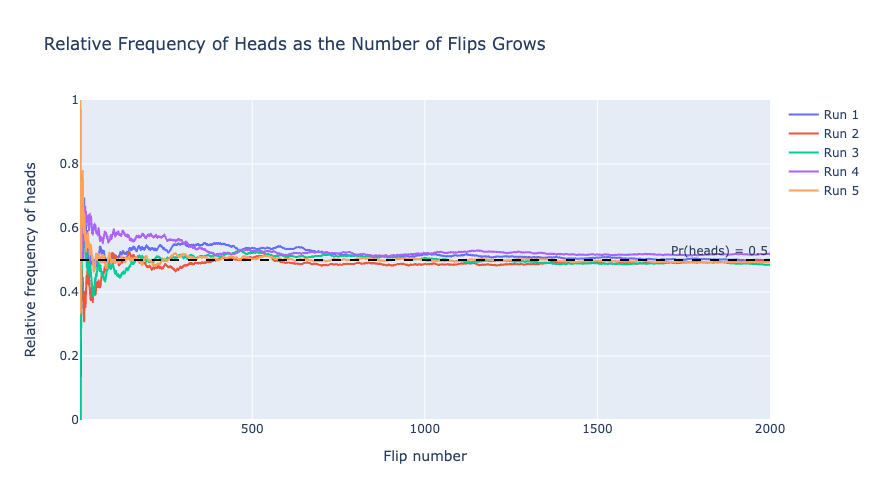

In [132]:
import plotly.express as px

N = 2000
flip_numbers = np.arange(1, N + 1)   # 1, 2, 3, ..., 2000
results = pd.DataFrame({"Flip number": flip_numbers})

for run in ["Run 1", "Run 2", "Run 3", "Run 4", "Run 5"]:
    flips = np.random.randint(low = 0, high = 2, size = N)
    results[run] = np.cumsum(flips) / flip_numbers   # relative frequency of heads after each flip

fig = px.line(results, x = "Flip number", y = ["Run 1", "Run 2", "Run 3", "Run 4", "Run 5"],
              labels = {"value": "Relative frequency of heads", "variable": ""},
              title = "Relative Frequency of Heads as the Number of Flips Grows",
              range_y = [0, 1], height = 500)
fig.add_hline(y = 0.5, line_dash = "dash", line_color = "black",
              annotation_text = "Pr(heads) = 0.5", annotation_position = "top right")

**What do we see?**

* At the start, the relative frequency swings wildly. (After one flip it can only be 0 or 1; after three flips it can only be 0, 1/3, 2/3, or 1.)
* As the number of flips grows, all five runs converge toward 0.5.
* The runs take *different paths* but end up at the *same destination*.

This phenomenon is an example of the **Law of Large Numbers**: as the number of repetitions grows, the relative frequency of an event gets closer and closer to the probability of that event. It's the reason the relative frequency interpretation makes sense.

### Watching probability emerge: random draws from the Titanic

Earlier we found that $\text{Pr(survived)} = 0.322157$ by *counting*: the fraction of the 2207 passengers who survived was 711/2207 = 0.322157. The relative frequency interpretation makes a prediction: if we repeat "pick a passenger at random" many times, the relative frequency of survivors should converge to 0.322157.

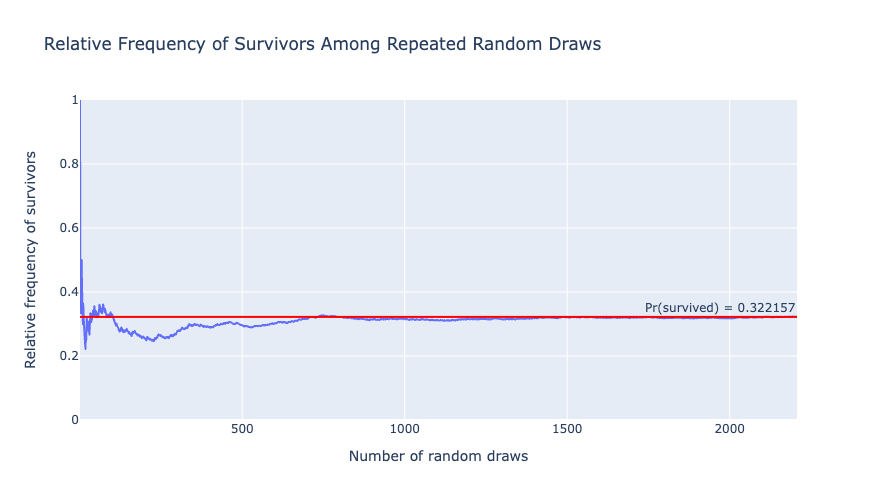

In [117]:
N = len(titanic)
random_draws = titanic.sample(frac=1)    

random_draws_surv = (random_draws["survived"] == "yes").to_numpy()
running_rel_freq = np.cumsum(random_draws_surv) / np.arange(1, N + 1)

fig = px.line(x = np.arange(1, N + 1), y = running_rel_freq,
              labels = {"x": "Number of random draws", "y": "Relative frequency of survivors"},
              title = "Relative Frequency of Survivors Among Repeated Random Draws",
              range_y = [0, 1], height = 500)
fig.add_hline(y = titanic["survived"].value_counts(normalize = True).get("yes"), 
              line_dash = "solid", line_color = "red",
              annotation_text = "Pr(survived) = 0.322157", 
              annotation_position = "top right")
fig.update_traces(showlegend = False)

**What do we see?**

* Like the coin flipping example, early on, the relative frequency swings wildly. 
* But as the number of draws grows (and approaches the full population), the relative frequency approaches the population proportion (probability)

So, we have two different routes to a probability, and they agree:

* **Counting:** the fraction of the population that has the characteristic.
* **Relative frequency:** the long-run proportion of repeated random draws that have the characteristic.

### 💻 ACTIVITY: Estimating probabilities by simulation

The relative frequency definition of probability provides a practical tool: **if we can't (or don't want to) calculate a probability exactly, we can estimate it by simulating the random process many times** and computing the relative frequency of the event.

Let's test that idea on a problem where we *know* the answer. In a previous activity, you found that out of the 36 equally likely outcomes of two dice, 6 had a total of 7, 6 were doubles, and 11 included a 6. So the exact probabilities are 6/36 $\approx$ 0.1667, 6/36 $\approx$ 0.1667, and 11/36 $\approx$ 0.3056.

1. Complete the code below to simulate `N` rolls of two dice and estimate each of the three probabilities by relative frequency.
2. How close are your estimates to the exact values?
3. Change `N` to 100, then 1000, then 1000000. Run each version a few times. How does the run-to-run *wobble* of your estimates change with the number of rolls? (Does this remind you of anything from the last lecture?)

In [ ]:
N = 100

red   = np.random.randint(low = 1, high = 7, size = N)
green = ____                                      # fill in: the green die

total_is_7 = (red + green) == 7
doubles    = ____                                # fill in: both dice match
has_a_6    = ____                                # fill in: at least one die shows a 6

print("P(total is 7) is approximately", total_is_7.mean())
print("P(doubles) is approximately   ", doubles.mean())
print("P(at least one 6) is approx.  ", has_a_6.mean())

<details>
<summary><b>Show Solution</b></summary>

```python
N = 10000

red  = np.random.randint(low = 1, high = 7, size = N)
green = np.random.randint(low = 1, high = 7, size = N)

total_is_7 = ((red + green) == 7)
doubles    = (red == green)
has_a_6    = (red == 6) | (green == 6)

print("P(total is 7) is approximately", total_is_7.mean())
print("P(doubles) is approximately   ", doubles.mean())
print("P(at least one 6) is approx.  ", has_a_6.mean())
```

With 10,000 rolls the estimates are typically within a percentage point or so of 0.1667, 0.1667, and 0.3056. With only 100 rolls they're much more variable: *each run of the code is a different "sample" of rolls, and so gives a different estimate*. That is exactly the idea of a **sampling distribution** from the last lecture, and the same pattern appears: more data, less wobble.

</details>



### 👥 ACTIVITY: The birthday problem

Simulation lets us tackle questions that are hard to do in our heads. Here's a famous one.

> *In a room of $n$ people, what's the probability that **at least two** of them share a birthday?* 

Although outside the scope of *this* course, we can define this probability exactly, using the classical definition. Let $A$ be the event: 

> $A=$ in a room of $n$ people, at least two people share a birthday. 

It can be shown that (if we ignore February 29 and assume all 365 birthdays are equally likely) that $$\text{Pr}(A)=1-\frac{365\times354\times363\times\cdots\times(365-n+1)}{365^n}.$$ But because this is somewhat difficult to prove, we'll use the relative frequency approach instead.

**THINK.** How many people do you think the room needs before this probability is *greater than 0.5*? 

**PAIR.** Form a group of 3-4 classmates. Use the relative frequency idea to estimate the probability for a room of $n=$ 23 people:

* *One repetition:* pick 23 random birthdays (random integers from 1 to 365).
* *The event:* at least two of the birthdays are the same.
* *Repeat* many times, and compute the relative frequency of the event.

Complete the blank in the code below. (Hint: `np.unique(birthdays)` returns the *distinct* birthdays. If at least two people share one, there will be fewer distinct birthdays than people.) Then try other values of `n`. 

**SHARE.** What did you find? Did the answer surprise you? 

In [ ]:
n = 23
N = 1000

matches = []
for i in range(N):
    birthdays = np.random.randint(1, 366, size = n)   # one random birthday per person
    has_match = ____                                  # fill in: True if at least two birthdays are the same
    matches.append(has_match)

np.mean(matches)       # relative frequency of "at least one shared birthday"

<details>
<summary><b>Show Solution</b></summary>

```python
n = 23
N = 10000

matches = []
for i in range(N):
    birthdays = np.random.randint(1, 366, size = n)
    has_match = len(np.unique(birthdays)) < n
    matches.append(has_match)

np.mean(matches)     
```
</details>

With just 23 people the probability is already a bit over 0.5!

**Let's extend this:**
* repeat the investigation for *many* group sizes, constructing a plot of the probability across a range of potential group sizes, and
* compare the relative frequency value to the probability the classical definition provides. 

We begin by writing a `python` function to perform the classical calculation. But first, we re-write the equation above to be more "computer friendly". $$\text{Pr}(A)=1-\left(\frac{365-0}{365}\right)\times\left(\frac{365-1}{365}\right)\times\left(\frac{365-2}{365}\right)\times\cdots\times\left(\frac{365-(n-1)}{365}\right).$$

In [ ]:
# Define a function to perform the classical calculation
def calc_prob(n):
    prob = 1 - np.prod((365 - np.array(list(range(n))))/365)
    return prob

With that done, let's perform the investigation.

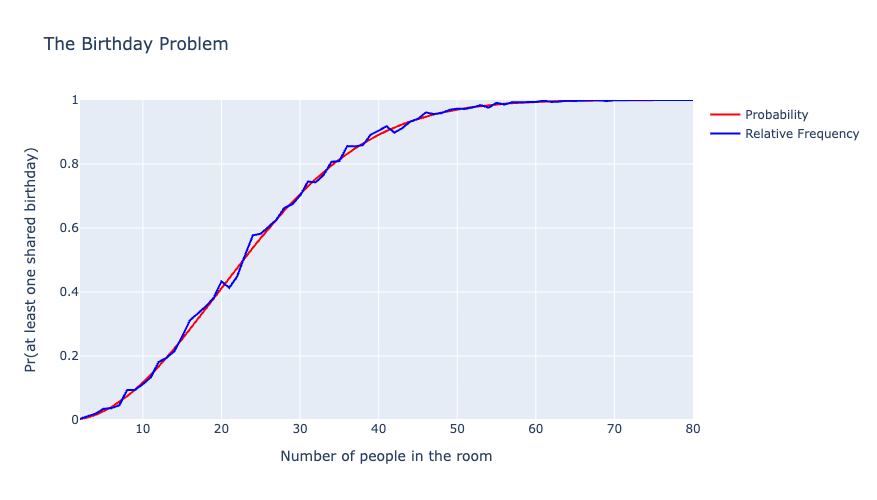

In [71]:
# Initialize result lists and repetition number
N = 1000
group_sizes = list(range(2, 81))
prob_match = []
rel_freq_match = []

# Perform calculations for each group size
for n in group_sizes:
    prob_match.append(calc_prob(n))
    matches = []
    for i in range(N):
        birthdays = np.random.randint(1, 366, size = n)
        matches.append(len(np.unique(birthdays)) < n)
    rel_freq_match.append(np.mean(matches))

# Organize results in a data frame
results = pd.DataFrame({"n":group_sizes,
                        "Probability":prob_match,
                        "Relative Frequency":rel_freq_match})    
   
# Visualize results
fig = px.line(results, x = "n", y = ["Probability","Relative Frequency"],
              labels = {"n": "Number of people in the room", 
                        "value": "Pr(at least one shared birthday)",
                        "variable": ""},
              title = "The Birthday Problem",
              color_discrete_sequence = ["red", "blue"],    
              range_y = [0, 1], height = 500)
fig.show()

Re-run the code above using different values of `N`. How does this impact the performance of the relative frequency calculation?

---
---

## Axioms of Probability

The word **axioms** is a fancy way of saying **rules**. There are three basic axioms (rules) that govern probabilities, which can be taken as fact. Some of them you have implicitly seen so far, but it's worth explicitly stating them here.

1. **Non-negativity:** The probability of an event cannot be negative: $\text{Pr}(A)\geq 0$.
    * This seems obvious from both the classical and relative frequency definitions provided above. Both are fractions based on counts. And counts can't be negative.
2. **Normalization:** The probability of *everything* that could possibly happen (i.e., the sample space) always adds up to 1. 
    * This means that *some* event in a sample space *must* occur.
    * Mathematically, this can be stated as $\text{Pr(sample space)}=1$.
3. **Additivity:** If two events cannot happen at the same time, the probability of one or the other happening is just their probabilities added together.
    * Said more precisely: if two events $A$ and $B$ are mutually exclusive, the probability that either $A$ happens or $B$ happens is $\text{Pr}(A)+\text{Pr}(B)$.
    * **Example:** The probability of rolling a die and getting a 1 or a 2 is $\text{Pr(roll 1 or 2) = Pr(roll 1) + Pr(roll 2)}$
    
There are some important consequences that arise because of these axioms. Again, some of these we've already seen, but they're worth stating explicity.

* **Probability Bound:** No event can have a probability greater than 1: $$\text{Pr}(A)\leq1$$
* **Complement Rule:** The probability of an event not happening is one minus the probability that it does: $$\text{Pr}(A \text{ doesn't happen})=1-\text{Pr}(A)$$
    * **Example:** $\text{Pr(head)} = 1 - \text{Pr(tail)}=\frac{1}{2}$
    * **Example:** The probability a randomly selected Titanic passenger survives is $\text{Pr(survives)}=0.3222$. Therefore, the probability a randomly selected Titanic passenger does not survive is $$\text{Pr(dies)}=1-\text{Pr(survives)} = 1 - 0.3222 = 0.6778$$


**Note:** there are *other* consequences of the axioms, but they're beyond the scope of what we need in this course, so they're not included.

---
---

## Key Takeaways

* **Probability** quantifies uncertainty with numbers instead of vague words.

* A **random process** has a **sample space** of possible **outcomes**; an **event** is a True/False statement about the outcome.

* The **probability of an event** quantifies how likely it is the event will occur. For event $A$: 
    * $\text{Pr}(A)$ is between 0 and 1 (inclusive).
    * The closer $\text{Pr}(A)$ is to 1, the more likely the event is.
    * The closer $\text{Pr}(A)$ is to 0, the less likely the event is.
    * $\text{Pr}(A \text{ doesn't happen})=1-\text{Pr}(A)$. That is, the probability an event *doesn't* occur is one minus the probability that it *does* occur.

* With equally likely outcomes, the **classic definition** of probability states that $\text{Pr}(A)$ is the fraction of outcomes in $A$. 

* The **relative frequency interpretation** says $\text{Pr}(A)$ is the *long-run* proportion of repetitions of the random process in which $A$ occurs. 
    * This lets us *estimate* probabilities by simulation. 
    * The fact that the relative frequency is indeed a good estimate of $\text{Pr}(A)$ is guaranteed by the **Law of Large Numbers**.



---

## Summary of New Tools

We came across a few new `numpy` and `pandas` tools, which are summarized below.

|Function / Method | Description |
| --- | --- |
|`np.random.choice(list)` | Picks one element of `list` at random |
|`np.random.randint(low, high, size)` | Generates `size` random whole numbers from `low` up to (but not including) `high` |
|`np.cumsum()` | Computes a running total |
|`np.arange(a, b)` | Generates the whole numbers from `a` up to (but not including) `b` |
|`np.unique()` | Returns the distinct values of an array |
|`s.mean()` for a boolean `s` | Returns the proportion of `True` values |

---
---

## Where We Go From Here

We now have what we need to understand sampling distributions in the language of probability.

Consider this random process:

> Take a simple random sample of $n$ passengers from the Titanic data, and compute the survival rate in the sample.

* The **outcome** is the sample survival rate (our estimate).
* Repeating the process many times and recording the estimate each time gives a collection of estimates.
* The histogram of those estimates, the **sampling distribution**, is a picture of relative frequencies.

So statements about sampling distributions are really **probability statements**. For example: "the probability the estimate lands in some range" is the relative frequency with which it did so, across repeated samples.

---
---